In [1]:
import matplotlib.pyplot as plt
import torch
from torchsom.core import SOM
from torchsom.visualization import SOMVisualizer, VisualizationConfig
    
import torchvision
import cv2
import numpy as np

In [2]:
image = cv2.imread("../data/impression-sunrise.jpg")
image.shape

(700, 900, 3)

In [3]:
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = image.astype(np.float32)/255.0
print(f"{np.max(image)}")

1.0


In [4]:
pixels = image.reshape(-1,3)
pixels.shape

(630000, 3)

In [5]:
pixels = torch.from_numpy(pixels)
pixels.shape

torch.Size([630000, 3])

In [6]:
random_seed = 42
torch.manual_seed(random_seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
side = 4   # 4, 8 ou 16

som = SOM(
    x=side, y=side,
    num_features=3,
    sigma=side / 2,
    learning_rate=0.5,
    epochs=30,
    batch_size=512,
    neighborhood_order=1,
    topology="rectangular",
    distance_function="euclidean",
    neighborhood_function="gaussian",
    lr_decay_function="lr_inverse_decay_to_zero",
    sigma_decay_function="sig_inverse_decay_to_one",
    search_backend="torch",
    random_seed=42,
    device=device,
)
som.initialize_weights(data=pixels, mode="random")
QE, TE = som.fit(data=pixels)
print(f"QE final = {QE[-1]:.4f} | TE final = {TE[-1]:.4f}")

Training SOM: 100%|██████████| 30/30 [01:09<00:00,  2.33s/epoch]

QE final = 0.0701 | TE final = 0.0974


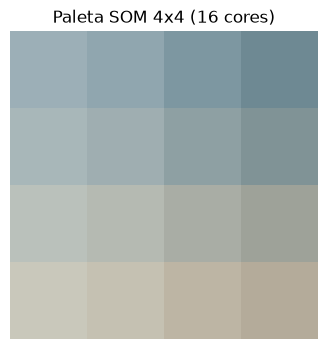

In [8]:
w = som.weights.detach().cpu()

palette = w.reshape(-1, 3).clamp(0, 1)
grid = palette.reshape(side, side, 3).numpy()

plt.figure(figsize=(4, 4))
plt.imshow(grid)
plt.title(f"Paleta SOM {side}x{side} ({side*side} cores)")
plt.axis("off")
plt.show()

In [9]:
@torch.no_grad()
def reconstruct(img, palette, chunk=200_000):
    H, W, _ = img.shape
    pix = torch.from_numpy(img.reshape(-1, 3)).float()
    pal = palette.float()
    bmu = torch.empty(len(pix), dtype=torch.long)
    dist = torch.empty(len(pix))
    for i in range(0, len(pix), chunk):
        d = torch.cdist(pix[i:i+chunk], pal)          # [n, K]
        m = d.min(dim=1)
        bmu[i:i+chunk], dist[i:i+chunk] = m.indices, m.values
    recon = pal[bmu].reshape(H, W, 3).numpy()         # troca cada pixel pela cor do BMU
    return recon, bmu, dist

recon, bmu, dist = reconstruct(image, palette)

QE=0.0698 | MSE=0.00363 | PSNR=24.40 dB


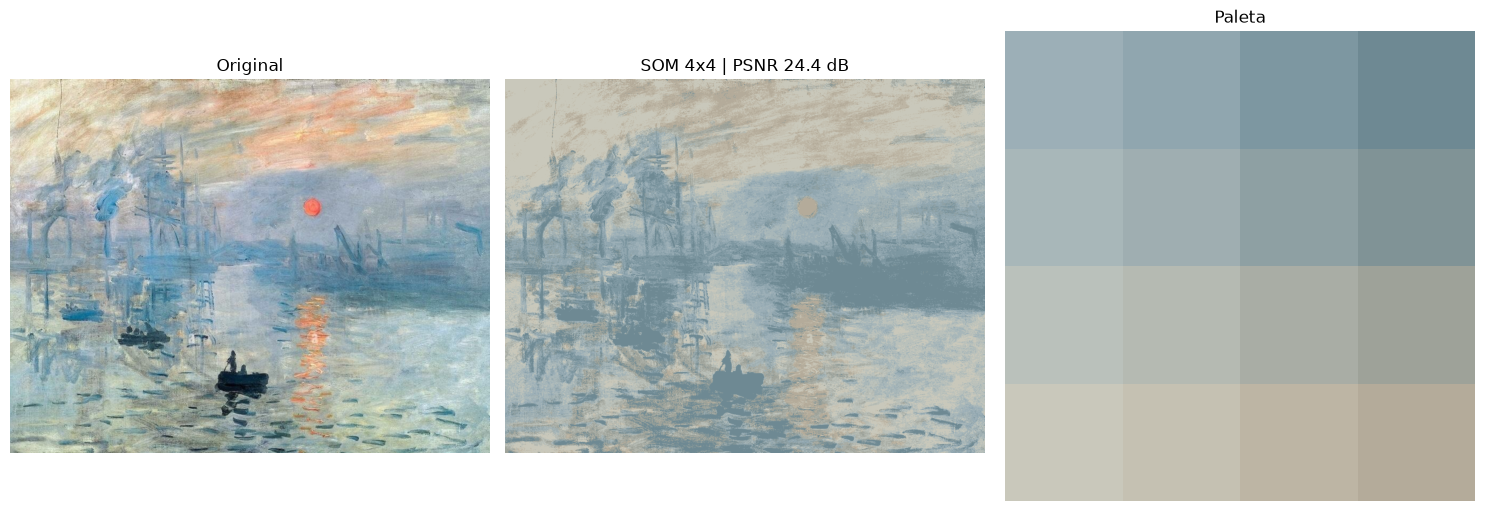

In [10]:
mse  = float(((image - recon) ** 2).mean())
psnr = 10 * np.log10(1.0 / mse)
qe   = float(dist.mean())
print(f"QE={qe:.4f} | MSE={mse:.5f} | PSNR={psnr:.2f} dB")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image);   ax[0].set_title("Original")
ax[1].imshow(recon); ax[1].set_title(f"SOM {side}x{side} | PSNR {psnr:.1f} dB")
ax[2].imshow(grid, interpolation="nearest"); ax[2].set_title("Paleta")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [11]:
side = 8   # 4, 8 ou 16

som = SOM(
    x=side, y=side,
    num_features=3,
    sigma=side / 2,
    learning_rate=0.5,
    epochs=30,
    batch_size=512,
    neighborhood_order=1,
    topology="rectangular",
    distance_function="euclidean",
    neighborhood_function="gaussian",
    lr_decay_function="lr_inverse_decay_to_zero",
    sigma_decay_function="sig_inverse_decay_to_one",
    search_backend="torch",
    random_seed=42,
    device=device,
)
som.initialize_weights(data=pixels, mode="random")
QE, TE = som.fit(data=pixels)
print(f"QE final = {QE[-1]:.4f} | TE final = {TE[-1]:.4f}")

Training SOM: 100%|██████████| 30/30 [01:13<00:00,  2.45s/epoch]

QE final = 0.0396 | TE final = 0.0570


torch.Size([8, 8, 3])


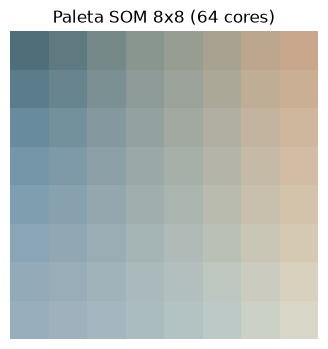

In [12]:
w = som.weights.detach().cpu()
print(w.shape)    # esperado: [side, side, 3]; se vier [side*side, 3], use o reshape abaixo

palette = w.reshape(-1, 3).clamp(0, 1)                # [K, 3], uma cor por neurônio
grid = palette.reshape(side, side, 3).numpy()         # paleta na forma do grid

plt.figure(figsize=(4, 4))
plt.imshow(grid, interpolation="nearest")
plt.title(f"Paleta SOM {side}x{side} ({side*side} cores)")
plt.axis("off")
plt.show()

QE=0.0394 | MSE=0.00137 | PSNR=28.63 dB | neurônios mortos=0


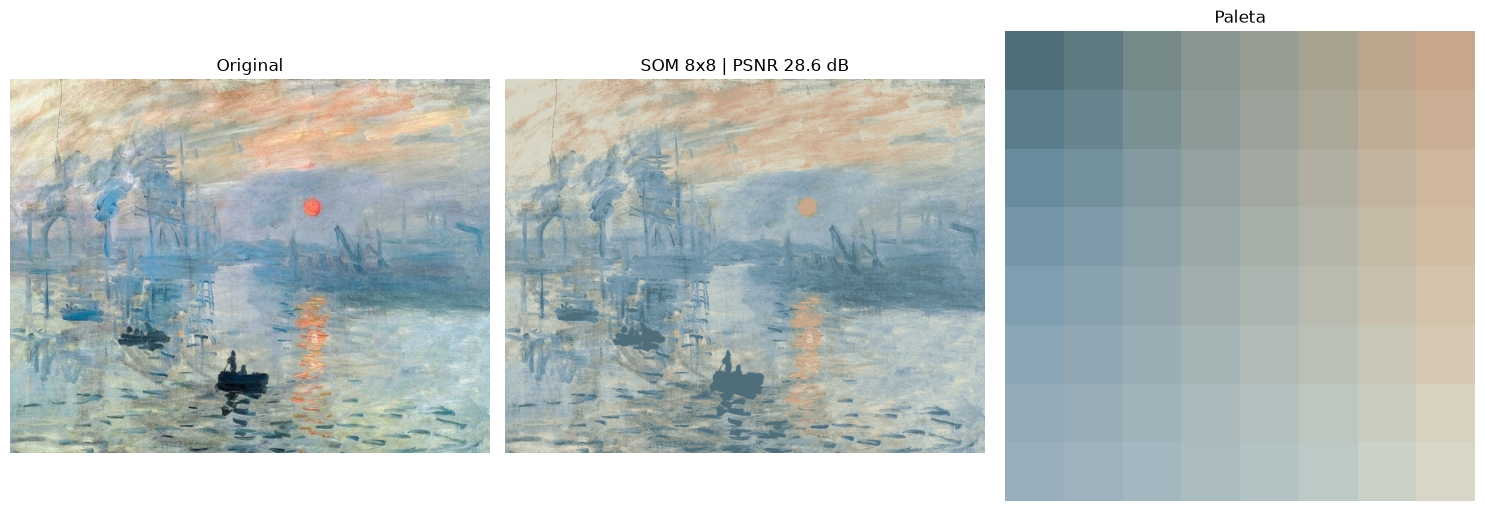

In [13]:
recon, bmu, dist = reconstruct(image, palette)
mse  = float(((image - recon) ** 2).mean())
psnr = 10 * np.log10(1.0 / mse)
qe   = float(dist.mean())
dead = int((torch.bincount(bmu, minlength=len(palette)) == 0).sum())
print(f"QE={qe:.4f} | MSE={mse:.5f} | PSNR={psnr:.2f} dB | neurônios mortos={dead}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image);   ax[0].set_title("Original")
ax[1].imshow(recon); ax[1].set_title(f"SOM {side}x{side} | PSNR {psnr:.1f} dB")
ax[2].imshow(grid, interpolation="nearest"); ax[2].set_title("Paleta")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [14]:
side = 16   # 4, 8 ou 16

som = SOM(
    x=side, y=side,
    num_features=3,
    sigma=side / 2,
    learning_rate=0.5,
    epochs=30,
    batch_size=512,
    neighborhood_order=1,
    topology="rectangular",
    distance_function="euclidean",
    neighborhood_function="gaussian",
    lr_decay_function="lr_inverse_decay_to_zero",
    sigma_decay_function="sig_inverse_decay_to_one",
    search_backend="torch",
    random_seed=42,
    device=device,
)
som.initialize_weights(data=pixels, mode="random")
QE, TE = som.fit(data=pixels)
print(f"QE final = {QE[-1]:.4f} | TE final = {TE[-1]:.4f}")

Training SOM: 100%|██████████| 30/30 [01:08<00:00,  2.30s/epoch]

QE final = 0.0246 | TE final = 0.2142


torch.Size([16, 16, 3])


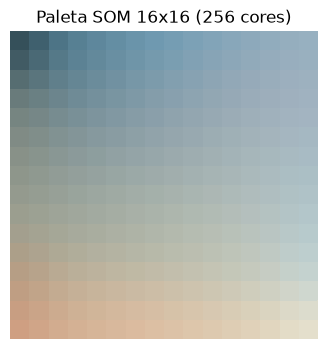

In [15]:
w = som.weights.detach().cpu()
print(w.shape)    # esperado: [side, side, 3]; se vier [side*side, 3], use o reshape abaixo

palette = w.reshape(-1, 3).clamp(0, 1)                # [K, 3], uma cor por neurônio
grid = palette.reshape(side, side, 3).numpy()         # paleta na forma do grid

plt.figure(figsize=(4, 4))
plt.imshow(grid, interpolation="nearest")
plt.title(f"Paleta SOM {side}x{side} ({side*side} cores)")
plt.axis("off")
plt.show()

QE=0.0245 | MSE=0.00051 | PSNR=32.93 dB | neurônios mortos=0


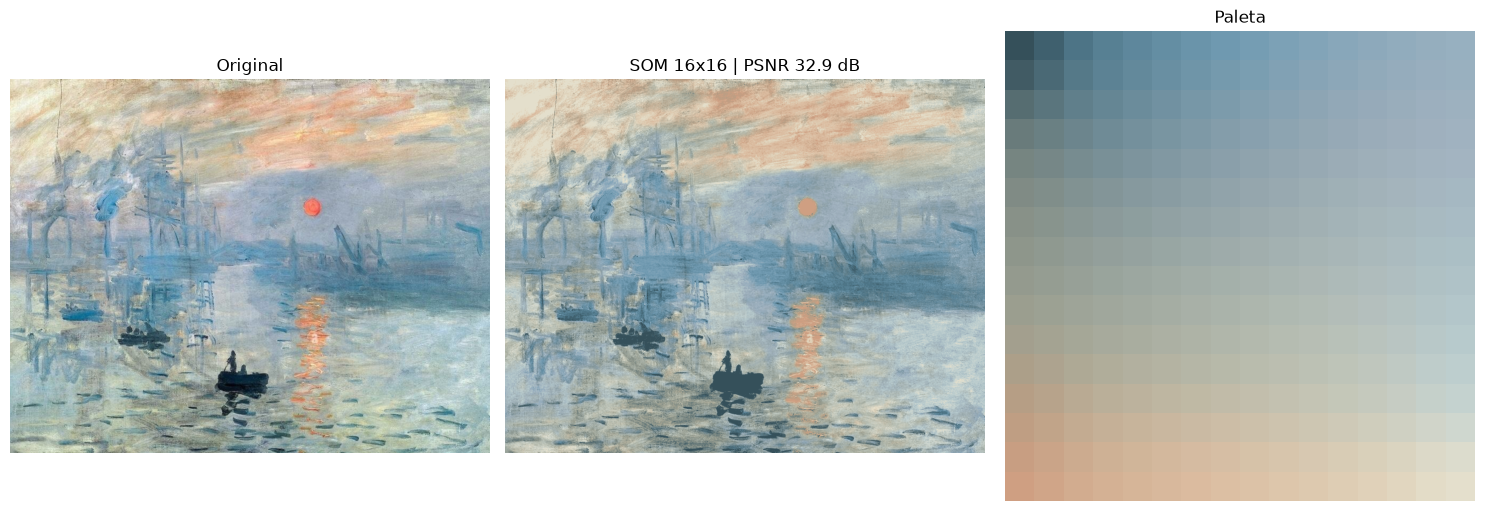

In [16]:
recon, bmu, dist = reconstruct(image, palette)
mse  = float(((image - recon) ** 2).mean())
psnr = 10 * np.log10(1.0 / mse)
qe   = float(dist.mean())
dead = int((torch.bincount(bmu, minlength=len(palette)) == 0).sum())
print(f"QE={qe:.4f} | MSE={mse:.5f} | PSNR={psnr:.2f} dB | neurônios mortos={dead}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image);   ax[0].set_title("Original")
ax[1].imshow(recon); ax[1].set_title(f"SOM {side}x{side} | PSNR {psnr:.1f} dB")
ax[2].imshow(grid, interpolation="nearest"); ax[2].set_title("Paleta")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

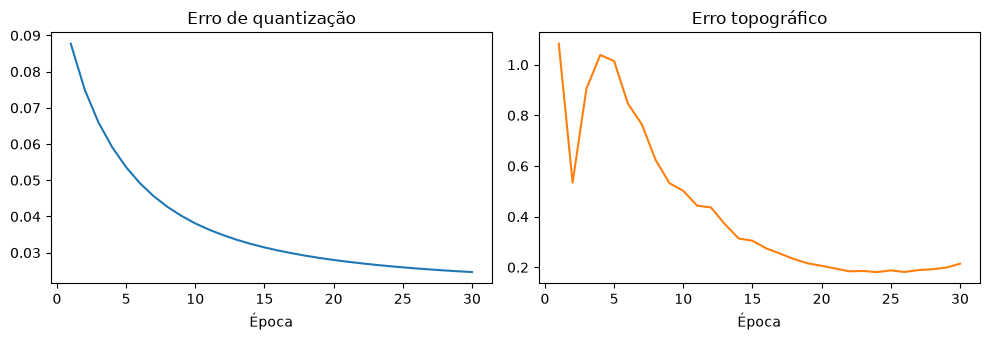

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, len(QE) + 1), QE); ax[0].set_title("Erro de quantização"); ax[0].set_xlabel("Época")
ax[1].plot(range(1, len(TE) + 1), TE, color="tab:orange"); ax[1].set_title("Erro topográfico"); ax[1].set_xlabel("Época")
plt.tight_layout(); plt.show()